# 01 · Exploring the demand data

Three years (2023–2025) of daily shipments for 10 SKUs out of a consumer-goods distribution center,
generated by `src/generate_data.py`. Goal: understand the patterns a forecast has to capture
(trend, seasonality, weekday effects, holidays and promotions) before building any model.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Find the project root, so the notebook works no matter where it is launched from.
here = Path.cwd()
ROOT = next(p for p in [here, *here.parents] if (p / "data" / "raw" / "sales.csv").exists())
df = pd.read_csv(ROOT / "data" / "raw" / "sales.csv", parse_dates=["date"])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10960 entries, 0 to 10959
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   date        10960 non-null  datetime64[us]
 1   sku         10960 non-null  str           
 2   category    10960 non-null  str           
 3   units_sold  10960 non-null  int64         
 4   on_promo    10960 non-null  int64         
 5   unit_price  10960 non-null  float64       
dtypes: datetime64[us](1), float64(1), int64(2), str(2)
memory usage: 684.1 KB


## Three years at a glance

Total volume grew about **5.5%** in 2024 and **7.1%** in 2025. The total peaks in summer, but that is driven by
beverages, the largest category. The next sections show that other categories move the opposite way.

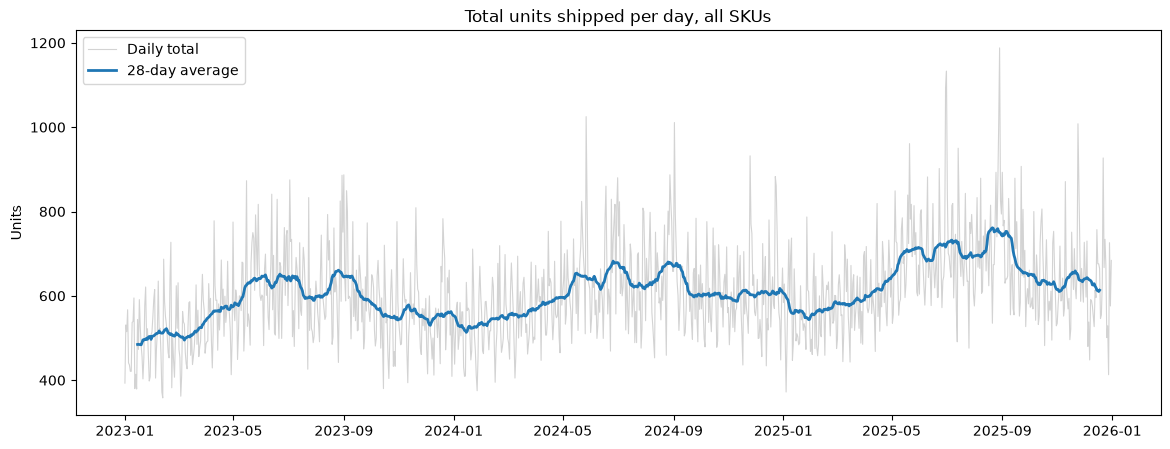

date
2023    208981
2024    220531
2025    236112
Name: units_sold, dtype: int64


In [2]:
daily = df.groupby("date")["units_sold"].sum()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(daily.index, daily.values, color="lightgray", linewidth=0.8, label="Daily total")
ax.plot(daily.index, daily.rolling(28, center=True).mean(), color="tab:blue", linewidth=2, label="28-day average")
ax.set_title("Total units shipped per day, all SKUs")
ax.set_ylabel("Units")
ax.legend()
plt.show()

print(df.groupby(df["date"].dt.year)["units_sold"].sum())

## Holiday spikes

Zooming in on the 2024 holiday season, the busiest days are **Nov 25** (the Monday before Thanksgiving) and
**Dec 23–24**, when stores restock ahead of the holidays. Most of these days had zero or one SKU on promotion,
so the spikes come from the holidays, not from promotions. A model has to tell the two apart.

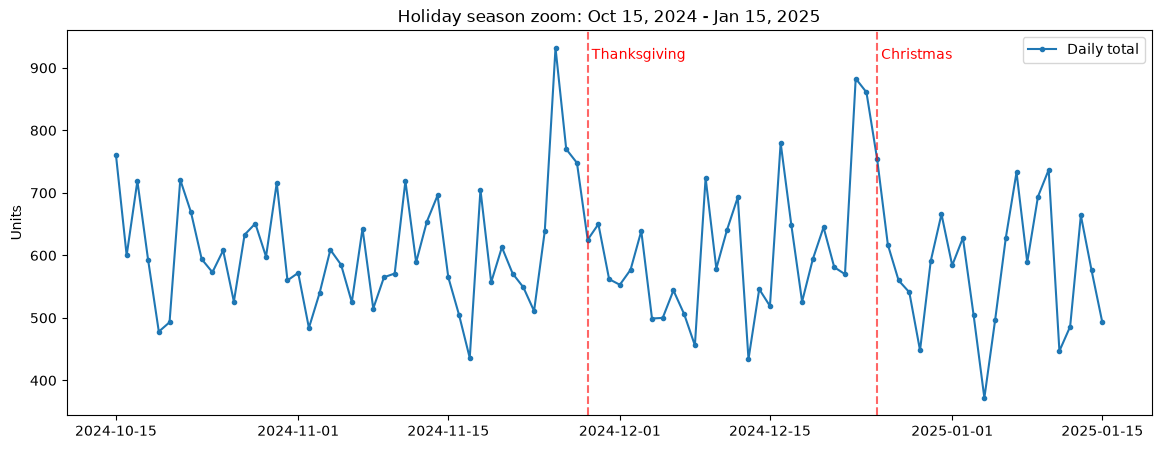

Busiest 5 days in this window:
            units  SKUs_on_promo
date                            
2024-11-25    932              1
2024-12-23    883              1
2024-12-24    861              0
2024-12-16    780              2
2024-11-26    770              0


In [3]:
window = daily["2024-10-15":"2025-01-15"]
promo_skus = df.groupby("date")["on_promo"].sum()["2024-10-15":"2025-01-15"]

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(window.index, window.values, marker="o", markersize=3, label="Daily total")
for name, day in [("Thanksgiving", "2024-11-28"), ("Christmas", "2024-12-25")]:
    ax.axvline(pd.Timestamp(day), color="red", linestyle="--", alpha=0.6)
    ax.text(pd.Timestamp(day), window.max(), f" {name}", color="red", va="top")
ax.set_title("Holiday season zoom: Oct 15, 2024 - Jan 15, 2025")
ax.set_ylabel("Units")
ax.legend()
plt.show()

print("Busiest 5 days in this window:")
print(pd.DataFrame({"units": window, "SKUs_on_promo": promo_skus}).nlargest(5, "units"))

## Weekday pattern and promotion lift

Shipments peak on **Monday (1.16× an average day)** and bottom out on **Saturday (0.86×)**, so labor should be
scheduled to that shape, not flat. Promotions lift sales by **34–59% depending on the SKU (47% on average)**.

In [4]:
# 1. Weekday pattern: each day's average compared with the overall average
weekday_avg = df.groupby(df["date"].dt.day_name())["units_sold"].mean()
weekday_index = (weekday_avg / weekday_avg.mean()).sort_values(ascending=False)
print("Weekday index (1.00 = average day):")
print(weekday_index.round(2))

# 2. Promotion lift: how much more each SKU sells on promo days
by_promo = df.groupby(["sku", "on_promo"])["units_sold"].mean().unstack()
by_promo.columns = ["normal_day", "promo_day"]
by_promo["lift_%"] = ((by_promo["promo_day"] / by_promo["normal_day"] - 1) * 100).round(0)
print("\nPromotion lift by SKU:")
print(by_promo.round(1))

Weekday index (1.00 = average day):
date
Monday       1.16
Tuesday      1.10
Wednesday    1.03
Thursday     0.99
Friday       0.96
Sunday       0.90
Saturday     0.86
Name: units_sold, dtype: float64

Promotion lift by SKU:
         normal_day  promo_day  lift_%
sku                                   
SKU-001       140.0      204.0    46.0
SKU-002        93.2      136.5    46.0
SKU-003        39.3       62.4    59.0
SKU-004       114.7      156.6    37.0
SKU-005        63.8       92.4    45.0
SKU-006        32.0       46.7    46.0
SKU-007        32.1       48.8    52.0
SKU-008        17.8       23.8    34.0
SKU-009        47.5       72.7    53.0
SKU-010        13.5       20.2    50.0


## Seasonality differs by category

**Beverages** swing from 0.65 in January to 1.31 in August, while **Household** and **Snacks** peak in December.
Adding everything together hides these opposite patterns, which is why forecasting is done per SKU.

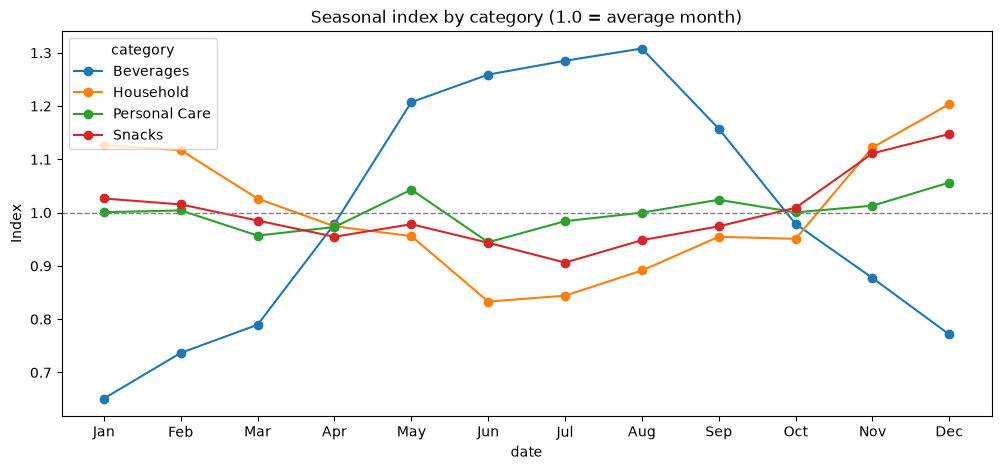

In [5]:
monthly = df.pivot_table(index=df["date"].dt.month, columns="category",
                         values="units_sold", aggfunc="mean")
seasonal_index = monthly / monthly.mean()

ax = seasonal_index.plot(figsize=(12, 5), marker="o")
ax.axhline(1.0, color="gray", linestyle="--", linewidth=1)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_title("Seasonal index by category (1.0 = average month)")
ax.set_ylabel("Index")
plt.show()